# My MLP vs pytorch

Comparing my mlp with the one from pytorch

In [25]:
import sys

sys.path.append("..")

from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch

In [26]:
def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed()

In [27]:
heart_disease = fetch_ucirepo(id=45)

X_raw: pd.DataFrame = heart_disease.data.features
y_raw: pd.Series = (heart_disease.data.targets["num"] > 0).astype(int)

In [28]:
mask = ~np.asarray(pd.isna(X_raw).any(axis=1))

X = X_raw[mask]
y = y_raw[mask]

In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

NUM_COLS = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]

prep = ColumnTransformer(
    transformers=[
        ("stand", StandardScaler(), NUM_COLS),
    ],
    remainder="passthrough",
)

In [30]:
from sklearn.model_selection import train_test_split

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y.to_numpy(), test_size=0.2, stratify=y, random_state=42
)

X_train = prep.fit_transform(X_train_raw)
X_test = prep.transform(X_test_raw)

In [31]:
from pytorch_helpers.dataloader import create_dataloader

train_loader = create_dataloader(X_train, y_train, batch_size=32, shuffle=True)

test_loader = create_dataloader(X_test, y_test, batch_size=32, shuffle=True)

In [32]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, log_loss
from models.loss_functions import LogLoss

def evaluate_pipe(pipe, X_test, y_test, round_to):
    y_prob = pipe.predict_proba(X_test)[:, 1]
    y_pred = pipe.predict(X_test)
    return {
        "loss": round(float(LogLoss().apply(y_test, y_prob).mean()), round_to),
        "accuracy": round(accuracy_score(y_test, y_pred), round_to),
        "f1": round(f1_score(y_test, y_pred, zero_division=0), round_to),
        "precision": round(precision_score(y_test, y_pred, zero_division=0), round_to),
        "recall": round(recall_score(y_test, y_pred, zero_division=0), round_to),
    }

In [33]:
from models.mlp import MultiLayerPerceptron
from models.activation_functions import ReLu
from models.loss_functions import LogLoss
from models.optimizer import Adam
from models.weight_initializer import HeInitializer

## Initial tests

### My implementation

In [34]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline

pipe = Pipeline(
    [
        (
            "clf",
            MultiLayerPerceptron(
                hidden_layer_sizes=[8],
                activation_function=ReLu(),
                loss_function=LogLoss(),
                weight_initializer=HeInitializer(random_state=42),
                optimizer=Adam(),
                batch_size=32,
                random_state=42,
                max_iter=100,
            ),
        ),
    ]
)

{'loss': 0.299274637, 'accuracy': 0.8666666667, 'f1': 0.8461538462, 'precision': 0.9166666667, 'recall': 0.7857142857}


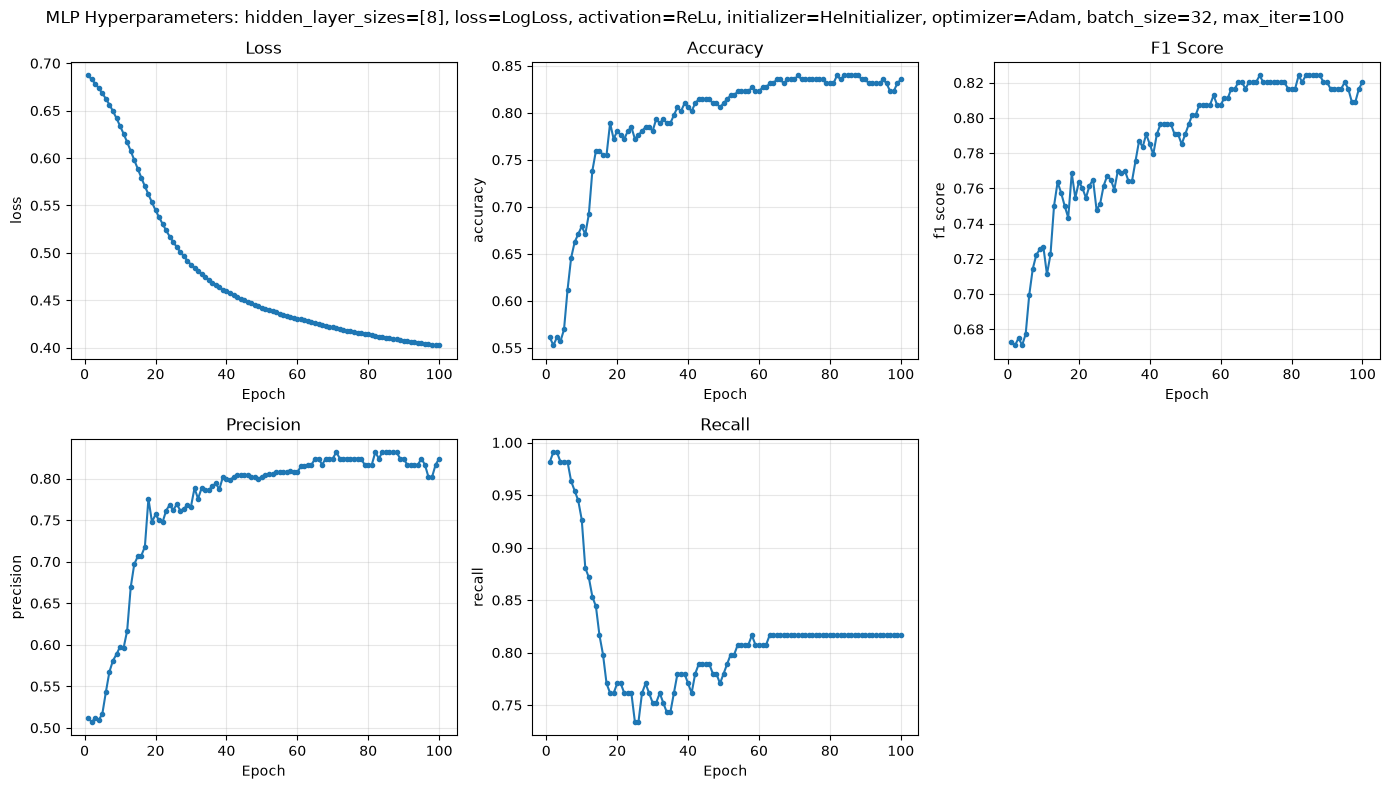

In [35]:
pipe.fit(X_train, y_train)

print(evaluate_pipe(pipe, X_test, y_test, 10))

pipe.named_steps["clf"].plot_history()
plt.show()

### Pytorch

In [36]:
from torch import nn

from pytorch_helpers.neuralnetwork import NeuralNetwork

set_seed(42)

device = (
    torch.accelerator.current_accelerator().type
    if torch.accelerator.is_available()
    else "cpu"
)

hidden_layer = nn.Linear(13, 8)
nn.init.kaiming_normal_(hidden_layer.weight, mode="fan_in", nonlinearity="relu")
nn.init.zeros_(hidden_layer.bias)

output_layer = nn.Linear(8, 1)
nn.init.normal_(output_layer.weight, mean=0, std=0.01)
nn.init.zeros_(output_layer.bias)

model = NeuralNetwork(
    architecture=nn.Sequential(
        hidden_layer,
        nn.ReLU(),
        output_layer,
        nn.Sigmoid()
    ),
)

loss_fn = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters())

In [37]:
from pytorch_helpers.training import TorchBinaryClassifier

clf = TorchBinaryClassifier(
    model=model,
    loss_fn=loss_fn,
    optimizer=optimizer,
    device=device,
)

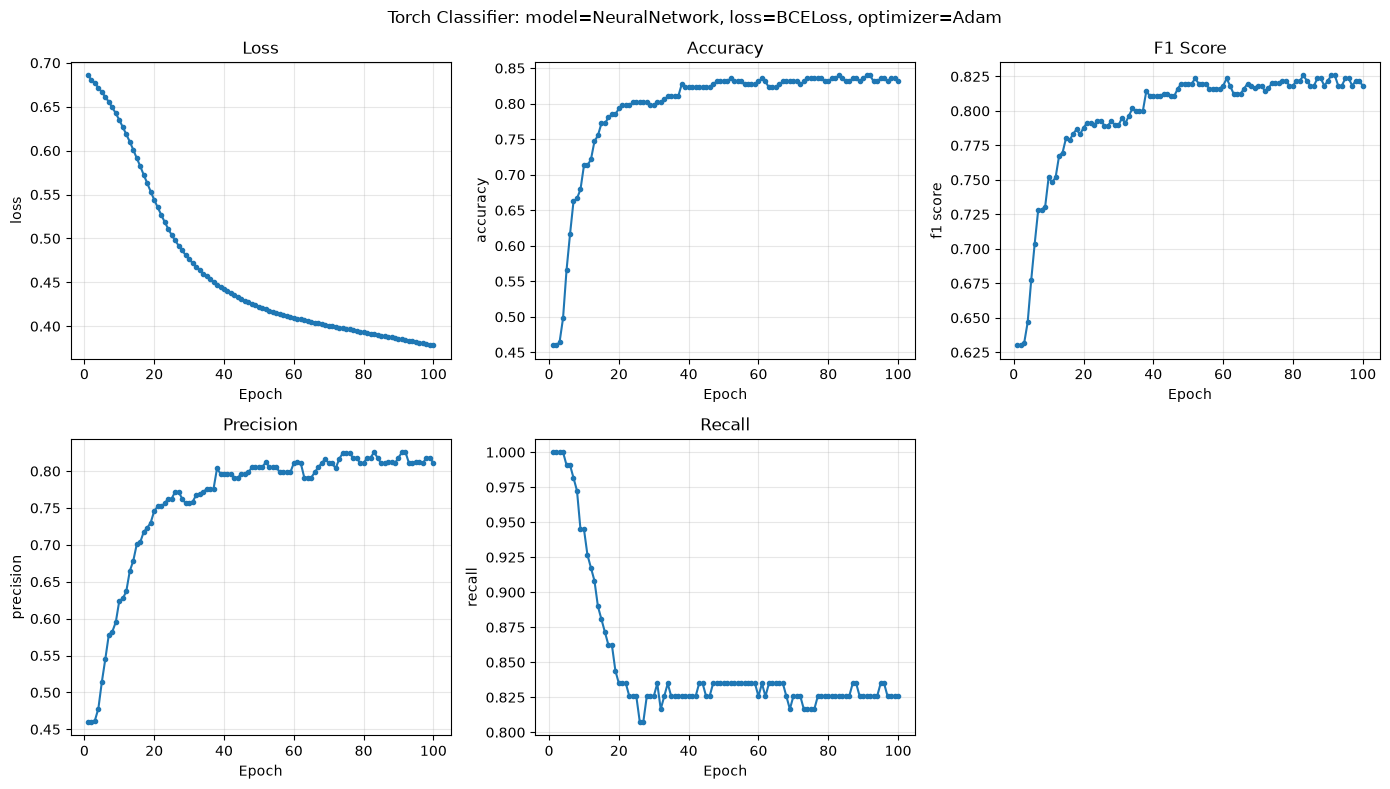

In [38]:
clf.train(
    dataloader=train_loader,
    max_iter=100,
    verbose=False,
)

clf.plot_history()
plt.show()

In [39]:
clf.evaluate(test_loader)

{'loss': 0.3088372588157654,
 'accuracy': 0.8833333333333333,
 'precision': 0.8888888888888888,
 'recall': 0.8571428571428571,
 'f1_score': 0.8727272727272727}

### Comparison

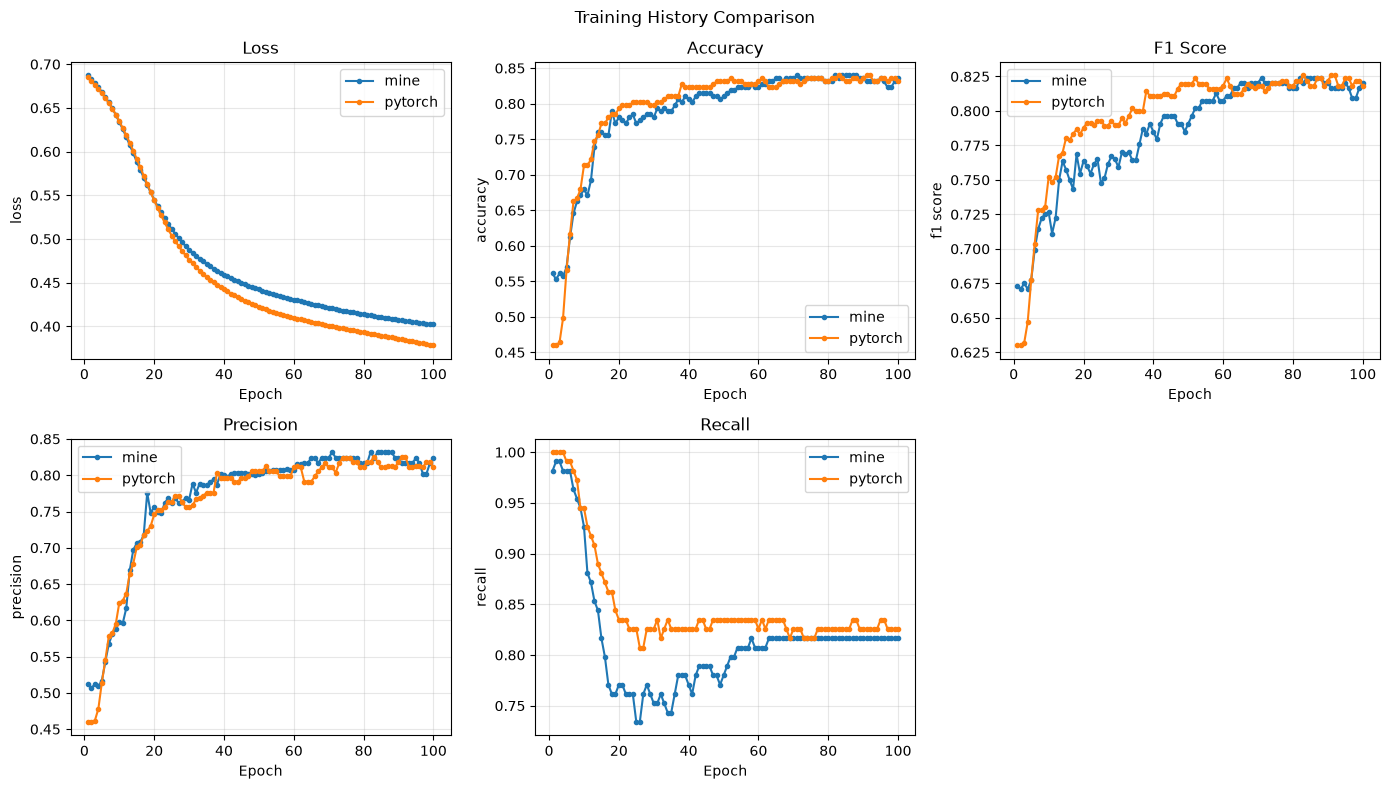

In [40]:
from helpers.training_history import plot_compare

plot_compare(
    ("mine", pipe.named_steps["clf"].history),
    ("pytorch", clf.history)
)

plt.show()

## The same initial weights

In [41]:
from sklearn.pipeline import Pipeline
from torch import nn

from models.loss_functions import PyTorchLogLoss
from pytorch_helpers.neuralnetwork import NeuralNetwork
from pytorch_helpers.training import TorchBinaryClassifier


mlp = MultiLayerPerceptron(
    hidden_layer_sizes=[8],
    activation_function=ReLu(),
    loss_function=LogLoss(),
    weight_initializer=HeInitializer(random_state=42),
    optimizer=Adam(),
    batch_size=32,
    random_state=42,
    max_iter=100,
    warm_start=True,
)

rng = np.random.default_rng(42)
mlp._initialize_layers(13, rng)

hidden_layer = nn.Linear(13, 8)
output_layer = nn.Linear(8, 1)

with torch.no_grad():
    hidden_layer.weight.copy_(torch.tensor(mlp.layers[0].weights_, dtype=torch.float32))
    hidden_layer.bias.copy_(torch.tensor(mlp.layers[0].biases_.ravel(), dtype=torch.float32))
    output_layer.weight.copy_(torch.tensor(mlp.layers[1].weights_, dtype=torch.float32))
    output_layer.bias.copy_(torch.tensor(mlp.layers[1].biases_.ravel(), dtype=torch.float32))


pipe = Pipeline([("clf", mlp)])

device = (
    torch.accelerator.current_accelerator().type
    if torch.accelerator.is_available()
    else "cpu"
)

model = NeuralNetwork(
    architecture=nn.Sequential(
        hidden_layer,
        nn.ReLU(),
        output_layer,
        nn.Sigmoid(),
    ),
)

clf = TorchBinaryClassifier(
    model=model,
    loss_fn=nn.BCELoss(),
    optimizer=torch.optim.Adam(model.parameters()),
    device=device,
)

mine: {'loss': 0.2987494417, 'accuracy': 0.8666666667, 'f1': 0.8461538462, 'precision': 0.9166666667, 'recall': 0.7857142857}
pytorch: {'loss': 0.29623770117759707, 'accuracy': 0.8666666666666667, 'precision': 0.9166666666666666, 'recall': 0.7857142857142857, 'f1_score': 0.8461538461538461}


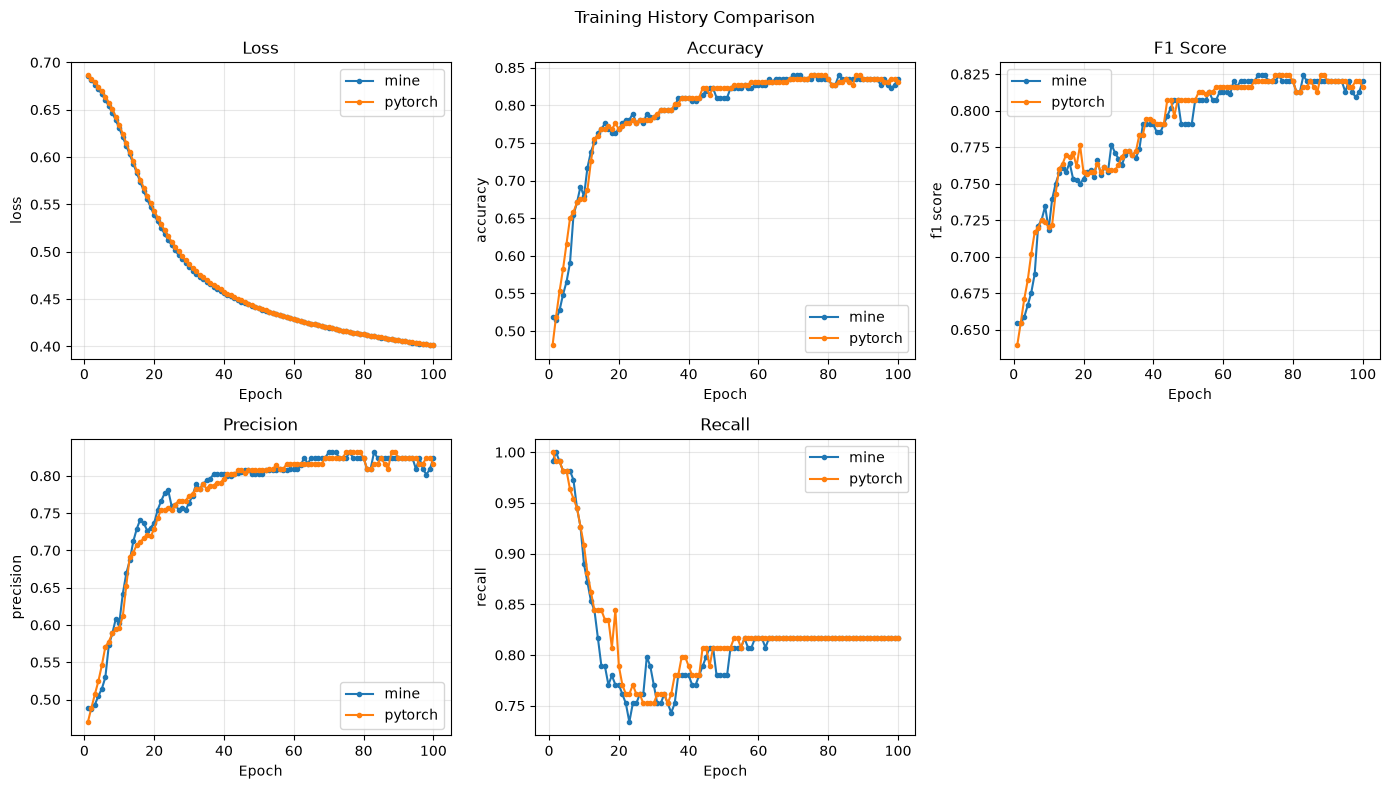

In [42]:
pipe.fit(X_train, y_train)
print("mine:", evaluate_pipe(pipe, X_test, y_test, 10))

clf.train(dataloader=train_loader, max_iter=100, verbose=False)
print("pytorch:", clf.evaluate(test_loader))

from helpers.training_history import plot_compare

plot_compare(
    ("mine", pipe.named_steps["clf"].history),
    ("pytorch", clf.history),
)
plt.show()

## Using PyTochLogLoss

In [43]:
from sklearn.pipeline import Pipeline
from torch import nn

from models.loss_functions import PyTorchLogLoss
from pytorch_helpers.neuralnetwork import NeuralNetwork
from pytorch_helpers.training import TorchBinaryClassifier


mlp = MultiLayerPerceptron(
    hidden_layer_sizes=[8],
    activation_function=ReLu(),
    loss_function=PyTorchLogLoss(),
    weight_initializer=HeInitializer(random_state=42),
    optimizer=Adam(),
    batch_size=32,
    random_state=42,
    max_iter=100,
    warm_start=True,
)

rng = np.random.default_rng(42)
mlp._initialize_layers(13, rng)

hidden_layer = nn.Linear(13, 8)
output_layer = nn.Linear(8, 1)

with torch.no_grad():
    hidden_layer.weight.copy_(torch.tensor(mlp.layers[0].weights_, dtype=torch.float32))
    hidden_layer.bias.copy_(torch.tensor(mlp.layers[0].biases_.ravel(), dtype=torch.float32))
    output_layer.weight.copy_(torch.tensor(mlp.layers[1].weights_, dtype=torch.float32))
    output_layer.bias.copy_(torch.tensor(mlp.layers[1].biases_.ravel(), dtype=torch.float32))


pipe = Pipeline([("clf", mlp)])

device = (
    torch.accelerator.current_accelerator().type
    if torch.accelerator.is_available()
    else "cpu"
)

model = NeuralNetwork(
    architecture=nn.Sequential(
        hidden_layer,
        nn.ReLU(),
        output_layer,
        nn.Sigmoid(),
    ),
)

clf = TorchBinaryClassifier(
    model=model,
    loss_fn=nn.BCELoss(),
    optimizer=torch.optim.Adam(model.parameters()),
    device=device,
)

mine: {'loss': 0.2987494417, 'accuracy': 0.8666666667, 'f1': 0.8461538462, 'precision': 0.9166666667, 'recall': 0.7857142857}
pytorch: {'loss': 0.2995584229628245, 'accuracy': 0.8666666666666667, 'precision': 0.9166666666666666, 'recall': 0.7857142857142857, 'f1_score': 0.8461538461538461}


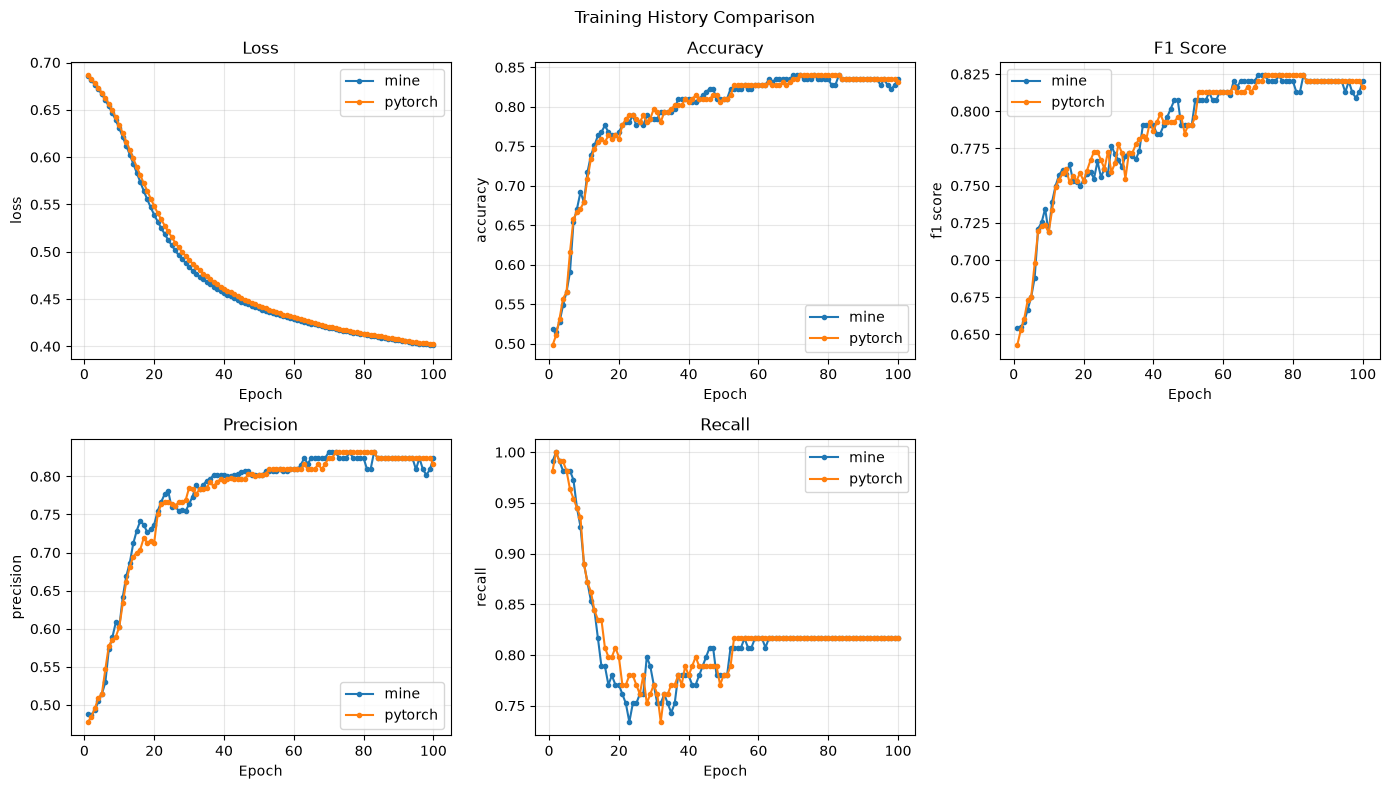

In [44]:
pipe.fit(X_train, y_train)
print("mine:", evaluate_pipe(pipe, X_test, y_test, 10))

clf.train(dataloader=train_loader, max_iter=100, verbose=False)
print("pytorch:", clf.evaluate(test_loader))

from helpers.training_history import plot_compare

plot_compare(
    ("mine", pipe.named_steps["clf"].history),
    ("pytorch", clf.history),
)
plt.show()

## Removing shuffling

In [45]:
from sklearn.pipeline import Pipeline
from torch import nn

from models.loss_functions import PyTorchLogLoss
from pytorch_helpers.neuralnetwork import NeuralNetwork
from pytorch_helpers.training import TorchBinaryClassifier

train_loader = create_dataloader(X_train, y_train, batch_size=32, shuffle=False)

test_loader = create_dataloader(X_test, y_test, batch_size=32, shuffle=False)

mlp = MultiLayerPerceptron(
    hidden_layer_sizes=[8],
    activation_function=ReLu(),
    loss_function=PyTorchLogLoss(),
    weight_initializer=HeInitializer(random_state=42),
    optimizer=Adam(),
    batch_size=32,
    shuffle=False,
    random_state=42,
    max_iter=100,
    warm_start=True,
)

rng = np.random.default_rng(42)
mlp._initialize_layers(13, rng)

hidden_layer = nn.Linear(13, 8)
output_layer = nn.Linear(8, 1)


with torch.no_grad():
    hidden_layer.weight.copy_(torch.tensor(mlp.layers[0].weights_, dtype=torch.float32))
    hidden_layer.bias.copy_(torch.tensor(mlp.layers[0].biases_.ravel(), dtype=torch.float32))
    output_layer.weight.copy_(torch.tensor(mlp.layers[1].weights_, dtype=torch.float32))
    output_layer.bias.copy_(torch.tensor(mlp.layers[1].biases_.ravel(), dtype=torch.float32))


pipe = Pipeline([("clf", mlp)])

device = (
    torch.accelerator.current_accelerator().type
    if torch.accelerator.is_available()
    else "cpu"
)

model = NeuralNetwork(
    architecture=nn.Sequential(
        hidden_layer,
        nn.ReLU(),
        output_layer,
        nn.Sigmoid(),
    ),
)

clf = TorchBinaryClassifier(
    model=model,
    loss_fn=nn.BCELoss(),
    optimizer=torch.optim.Adam(model.parameters()),
    device=device,
)

mine: {'loss': 0.3050568055, 'accuracy': 0.8833333333, 'f1': 0.8679245283, 'precision': 0.92, 'recall': 0.8214285714}
pytorch: {'loss': 0.3050568322340647, 'accuracy': 0.8833333333333333, 'precision': 0.92, 'recall': 0.8214285714285714, 'f1_score': 0.8679245283018868}


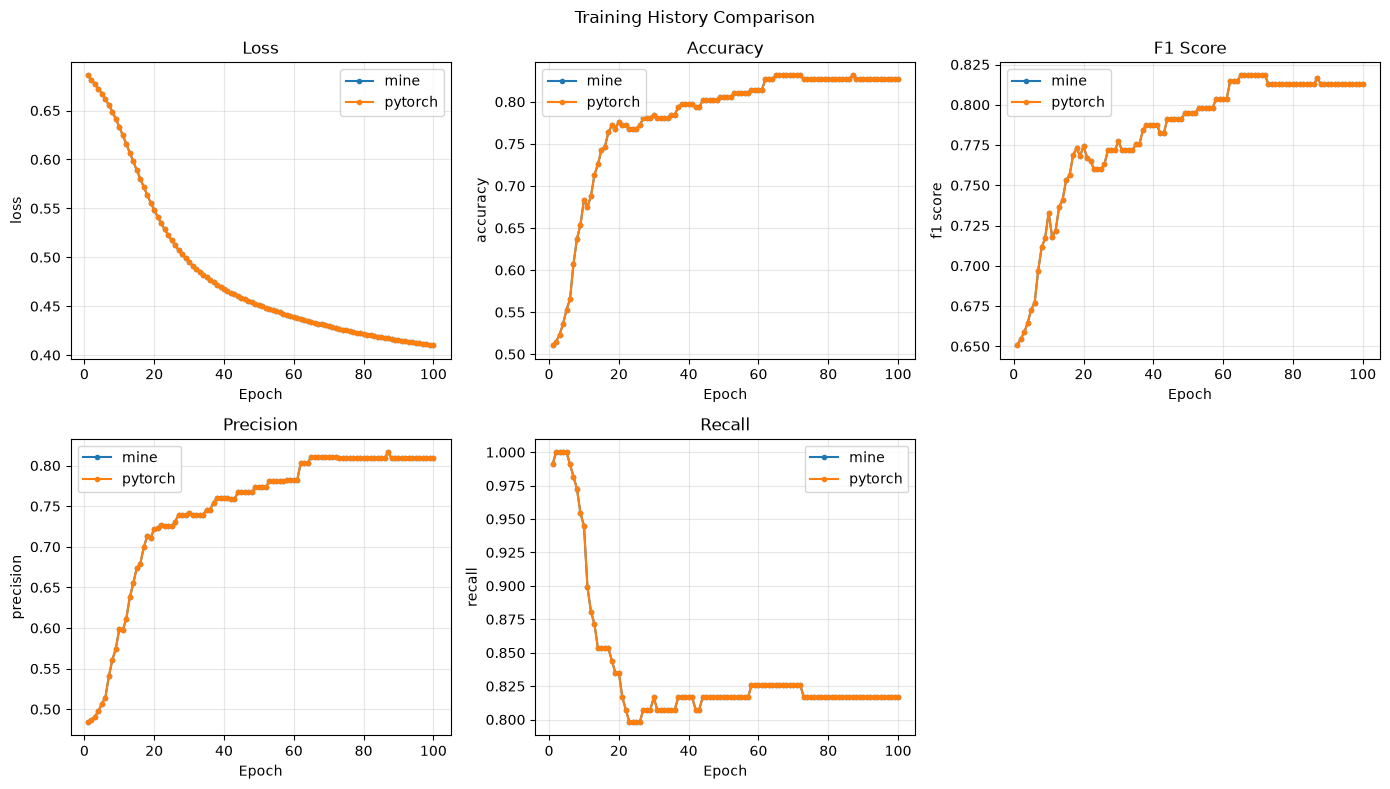

In [46]:
pipe.fit(X_train, y_train)
print("mine:", evaluate_pipe(pipe, X_test, y_test, 10))

clf.train(dataloader=train_loader, max_iter=100, verbose=False)
print("pytorch:", clf.evaluate(test_loader))

from helpers.training_history import plot_compare

plot_compare(
    ("mine", pipe.named_steps["clf"].history),
    ("pytorch", clf.history),
)
plt.show()

In [47]:
mine = pipe.named_steps["clf"]
torch_linears = [m for m in clf.model.architecture if isinstance(m, nn.Linear)]

for i, (layer, linear) in enumerate(zip(mine.layers, torch_linears)):
    print(f"=== layer {i} ===")
    print("mine weights:\n", layer.weights_)
    print("torch weights:\n", linear.weight.detach().cpu().numpy())
    print("mine biases:\n", layer.biases_)
    print("torch biases:\n", linear.bias.detach().cpu().numpy())
    print(
        "weights close:",
        np.allclose(layer.weights_, linear.weight.detach().cpu().numpy(), atol=1e-5),
    )
    print(
        "biases close:",
        np.allclose(layer.biases_.ravel(), linear.bias.detach().cpu().numpy(), atol=1e-5),
    )
    print()

=== layer 0 ===
mine weights:
 [[-0.08090514 -0.60309402  0.2555593   0.61149998 -1.19762777 -0.82983693
   0.09935532  0.0722558   0.49837028 -0.31536877 -0.07442268  0.5238558
   0.03133098]
 [ 0.46157757  0.25158903 -0.98622969  0.22177123 -0.42172682 -0.26453211
  -0.00173725  0.013204   -0.0546052   0.50672712 -0.24566975  0.08630832
  -0.16113635]
 [ 0.20878884  0.14333896  0.16188705  0.1689819   0.8400233  -0.15940908
  -0.20091813 -0.31918792  0.24160701  0.44281937 -0.04469387 -0.32953648
  -0.32338814]
 [ 0.26197574  0.4745515   0.17801965 -0.42886694  0.44689077  0.28593625
   0.26905696  0.28415937 -0.26907057  0.36726764  0.56383177  0.01236448
   0.432194  ]
 [-0.48764538  0.10655788 -0.19459571 -0.49217663  0.26416151  0.8296812
  -0.21126309  0.29452092 -1.0542894  -0.02029303  0.61618789  0.07615403
   0.43474758]
 [ 0.34897821 -0.30203125 -0.24695774  0.47410871 -0.31849963 -1.09304489
  -0.43302508 -0.15360624  0.54556937  0.23929807  0.05065299  0.09183702
   0.070